# __Competición CNN 2026. Clasificación binaria.__

Para esta competición, nuestro grupo ha decidido clasificar las imagenes del dataset de cartas debido a si son figuras o no. Esto corresponde a las cartas con valor de carácter en vez de numérico.

Se pretende agrupar las cartas en dos grandes grupos dependiendo de si tienen valor numérico o si son representadas por un caracter (A, J, Q, K, Joker).

## Instalación de librerías.

En este primer bloque se importan las librerías necesarias para trabajar en PyTorch, además del cálculo de métricas de evaluación. También se definen las rutas de los directorios y se fijan las semillas aleatorias para garantizar la reproducibilidad de los experimentos.

Los hiperparámetros que más hemos ido tocando (tamaño de imagen, batch size, épocas y paciencia del early stopping) los dejamos como constantes al principio de todo, así cuando queremos probar otro valor solo hay que cambiarlo aquí y no buscar por el cuaderno dónde estaba. La semilla es la 73 ya que es el número favorito de Sheldon Cooper!

In [1]:
import os
import shutil
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import transforms
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

ORIGEN_DIR = "cards"
DESTINO_DIR = "cards_reorganizado"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 80
PATIENCE = 13
SEED = 73

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Tenemos intención de correrlo en local, así que vamos a usar la GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cuda


### Descargar datasets. (Opcional)

En el caso de tener un token de kaggle configurado se puede descargar mediante los siguientes comandos de bash:

- kaggle datasets download -d cesarvidal/cards-dataset
- unzip -q cards-dataset.zip -d cards

## Reorganización del conjunto de datos para clasificación binaria

No nos escondemos, ya que en clase se dio permiso para que se usara la IA en este paso, le hemos pedido un código que a partir del dataset original dividido en 53 clases genere una nueva estructura de carpetas manteniendo intactas las particiones originales (train, valid y test). Las imágenes se agrupan en dos únicas categorías (esto sí ha sido decisión nuestra, cómo bien se ha comentado al principio del cuaderno): face_cards (ases, jotas, reinas, reyes y comodines) y non_face_cards (cartas numéricas del 2 al 10).

In [2]:
PALABRAS_FIGURA = ["ace", "jack", "queen", "king", "joker"]

# Si no existe la carpeta cards_reorganizado, la crea
if not os.path.exists(DESTINO_DIR):
    for split in ["train", "valid", "test"]:
        for clase in ["face_cards", "non_face_cards"]:
            os.makedirs(os.path.join(DESTINO_DIR, split, clase), exist_ok=True)
            
        split_path = os.path.join(ORIGEN_DIR, split)
        for carpeta_carta in os.listdir(split_path):
            carta_path = os.path.join(split_path, carpeta_carta)
            if os.path.isdir(carta_path):
                es_figura = any(p in carpeta_carta.lower() for p in PALABRAS_FIGURA)
                clase_destino = "face_cards" if es_figura else "non_face_cards"
                
                for archivo in os.listdir(carta_path):
                    if archivo.lower().endswith(".jpg"):
                        origen_img = os.path.join(carta_path, archivo)
                        nuevo_nombre = f"{carpeta_carta.replace(' ', '_')}_{archivo}"
                        destino_img = os.path.join(DESTINO_DIR, split, clase_destino, nuevo_nombre)
                        shutil.copy2(origen_img, destino_img)

TRAIN_DIR = os.path.join(DESTINO_DIR, "train")
VALID_DIR = os.path.join(DESTINO_DIR, "valid")
TEST_DIR  = os.path.join(DESTINO_DIR, "test")

### Carga y redimensionamiento de las imágenes

Se leen las imágenes desde las carpetas correspondientes a cada partición, se redimensionan a 224 x 224 píxeles  y se almacenan junto con sus etiquetas binarias (1 para figuras y 0 para cartas numéricas). Además, aunque no creamos que haga falta y confiemos en que todos los archivos estén correctos, hemos añadido una validación de archivos "corruptos", para que no dañe a futuro el entrenamiento.

In [3]:
def load_dataset(base_dir):
    images = []
    labels = []
    class_map = {"non_face_cards": 0, "face_cards": 1}
    
    for class_name, label in class_map.items():
        class_dir = os.path.join(base_dir, class_name)
        for filename in os.listdir(class_dir):
            if filename.lower().endswith(".jpg"):
                img_path = os.path.join(class_dir, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                    images.append(img)
                    labels.append(label)
                    
    return np.array(images), np.array(labels)

X_train, y_train = load_dataset(TRAIN_DIR)
X_val, y_val     = load_dataset(VALID_DIR)
X_test, y_test   = load_dataset(TEST_DIR)

print(f"Train: {X_train.shape}, Valid: {X_val.shape}, Test: {X_test.shape}")

Train: (7619, 224, 224, 3), Valid: (265, 224, 224, 3), Test: (265, 224, 224, 3)


### Observar algún dato.

Se seleccionan de forma aleatoria 8 imágenes del conjunto de entrenamiento y se muestran en una cuadrícula junto con su clase asignada para ver que todo está en orden.

Es una comprobación rápida pero útil. Por un lado vemos que las etiquetas tienen sentido (que una K o una Q no aparezca como numérica, por ejemplo). Por otro, que los colores se ven bien ya que OpenCV carga las imágenes en BGR y, si no se convirtiesen a RGB para pintarlas, las cartas rojas saldrían azules. Si algo de esto falla, mejor enterarse antes de entrenar que después.

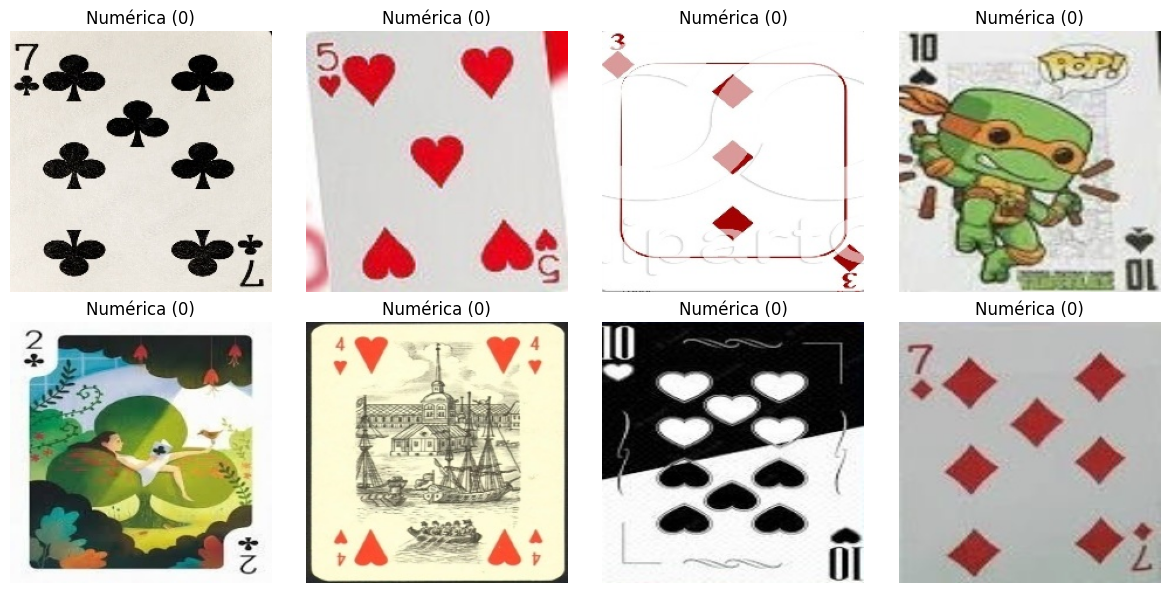

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
indices = random.sample(range(len(X_train)), 8)

for ax, idx in zip(axes.flat, indices):
    img_rgb = cv2.cvtColor(X_train[idx], cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    titulo = "Figura (1)" if y_train[idx] == 1 else "Numérica (0)"
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Análisis del dataset

Antes de preprocesar nada queremos saber cómo es el dataset con el que trabajamos, sobre todo si está equilibrado, como bien se ha comentado en clase.

train: mínimo 108, máximo 181, media 143.8 imágenes por tipo
valid: mínimo 5, máximo 5, media 5.0 imágenes por tipo
test: mínimo 5, máximo 5, media 5.0 imágenes por tipo


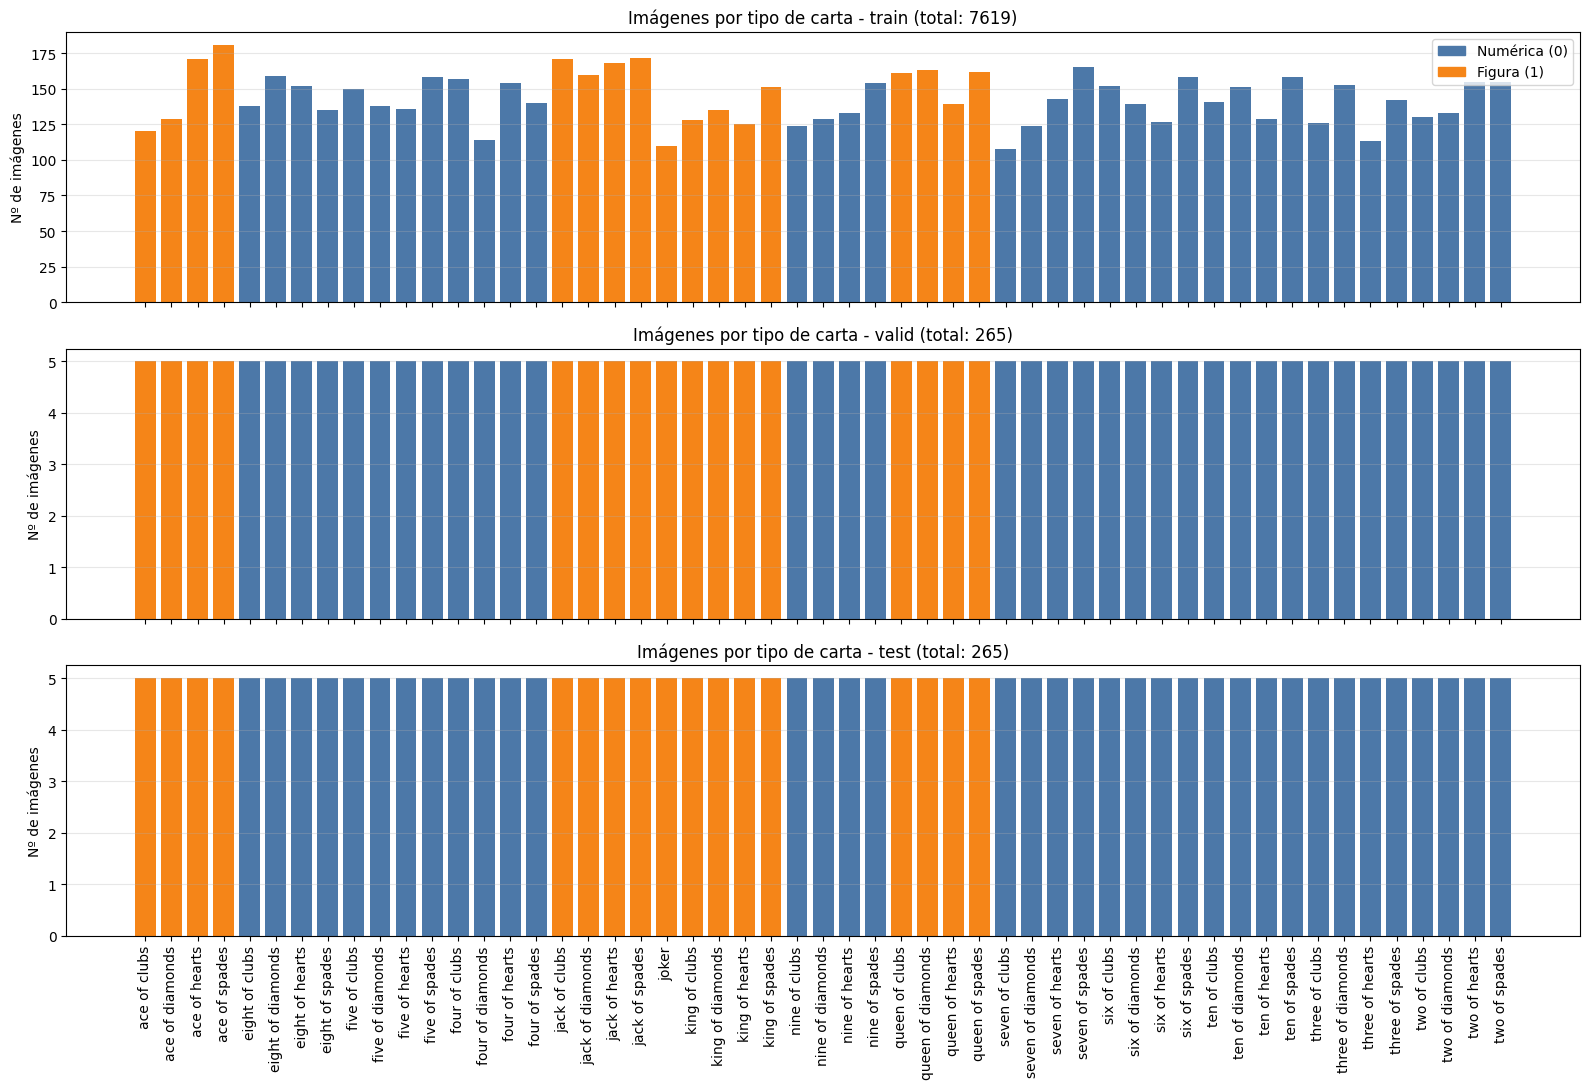

In [5]:
from matplotlib.patches import Patch

COLOR_NUM = "#4C78A8"   # cartas numéricas
COLOR_FIG = "#F58518"   # figuras

def contar_por_tipo(split):
    base = os.path.join(ORIGEN_DIR, split)
    conteo = {}
    for carpeta in sorted(os.listdir(base)):
        ruta = os.path.join(base, carpeta)
        if os.path.isdir(ruta):
            conteo[carpeta] = len(os.listdir(ruta))
    return conteo

conteos = {s: contar_por_tipo(s) for s in ["train", "valid", "test"]}
tipos = sorted(conteos["train"].keys())
colores = [COLOR_FIG if any(p in t.lower() for p in PALABRAS_FIGURA) else COLOR_NUM for t in tipos]

fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
for ax, split in zip(axes, ["train", "valid", "test"]):
    valores = [conteos[split].get(t, 0) for t in tipos]
    ax.bar(range(len(tipos)), valores, color=colores)
    ax.set_title(f"Imágenes por tipo de carta - {split} (total: {sum(valores)})")
    ax.set_ylabel("Nº de imágenes")
    ax.grid(axis="y", alpha=0.3)
    print(f"{split}: mínimo {min(valores)}, máximo {max(valores)}, media {np.mean(valores):.1f} imágenes por tipo")

axes[-1].set_xticks(range(len(tipos)))
axes[-1].set_xticklabels(tipos, rotation=90)
axes[0].legend(handles=[Patch(color=COLOR_NUM, label="Numérica (0)"), Patch(color=COLOR_FIG, label="Figura (1)")])
plt.tight_layout()
plt.savefig("imagenes_por_tipo.png", dpi=300)
plt.show()

Comprobamos también que no se nos haya quedado ninguna imagen sin cargar. Comparamos las imágenes que hay en las carpetas con las que realmente carga load_dataset y, si hay diferencia, enseñamos qué archivos son. Esto lo hacemos porque el enunciado dice que no se puede eliminar ninguna imagen de ninguna partición.

In [6]:
cargadas = {"train": len(X_train), "valid": len(X_val), "test": len(X_test)}

def archivos_no_cargados(split):
    base = os.path.join(ORIGEN_DIR, split)
    problemas = []
    for carpeta in os.listdir(base):
        ruta = os.path.join(base, carpeta)
        if not os.path.isdir(ruta):
            continue
        for archivo in os.listdir(ruta):
            ruta_img = os.path.join(ruta, archivo)
            if not archivo.lower().endswith(".jpg") or cv2.imread(ruta_img) is None:
                problemas.append(ruta_img)
    return problemas

for split in ["train", "valid", "test"]:
    en_disco = sum(conteos[split].values())
    print(f"{split}: {en_disco} en disco, {cargadas[split]} cargadas, diferencia: {en_disco - cargadas[split]}")
    if en_disco != cargadas[split]:
        for ruta_img in archivos_no_cargados(split):
            print("   no cargada:", ruta_img)

train: 7619 en disco, 7619 cargadas, diferencia: 0
valid: 265 en disco, 265 cargadas, diferencia: 0
test: 265 en disco, 265 cargadas, diferencia: 0


Ahora lo mismo, pero ya con las dos clases del problema. Aquí se ve el desbalanceo del que hablamos más abajo: hay bastantes más cartas numéricas que figuras obviamente (36 tipos de carta numérica frente a 17 de figura, contando el comodín), por eso en la función de pérdida usamos pos_weight.

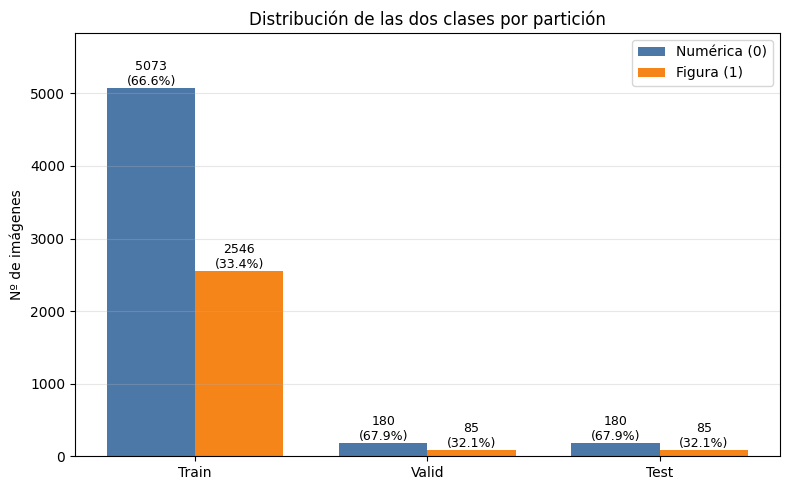

Relación numéricas/figuras en train: 1.99 (es el pos_weight de la función de pérdida)


In [7]:
nombres_split = ["Train", "Valid", "Test"]
n_num = [int((y == 0).sum()) for y in (y_train, y_val, y_test)]
n_fig = [int((y == 1).sum()) for y in (y_train, y_val, y_test)]
totales = [a + b for a, b in zip(n_num, n_fig)]

x = np.arange(3)
ancho = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - ancho / 2, n_num, ancho, label="Numérica (0)", color=COLOR_NUM)
b2 = ax.bar(x + ancho / 2, n_fig, ancho, label="Figura (1)", color=COLOR_FIG)
for barras, ns in ((b1, n_num), (b2, n_fig)):
    for barra, n, total in zip(barras, ns, totales):
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{n}\n({100 * n / total:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(nombres_split)
ax.set_ylabel("Nº de imágenes")
ax.set_title("Distribución de las dos clases por partición")
ax.set_ylim(0, max(n_num) * 1.15)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("distribucion_clases.png", dpi=300)
plt.show()

print(f"Relación numéricas/figuras en train: {n_num[0] / n_fig[0]:.2f} (es el pos_weight de la función de pérdida)")

## Preprocesamiento, Data Augmentation y creación de DataLoaders

Pasamos las imágenes de formato BGR a RGB, se normalizan al rango [0, 1] y se reorganizan sus dimensiones al formato esperado por PyTorch, es decir: N, Canales, Alto, Ancho. 

Además, se define un data augmentation aplicado exclusivamente al conjunto de entrenamiento, formado por un volteo horizontal aleatorio y una rotación de hasta 5 grados. Finalmente, no hemos puesto esto, pero hemos querido dejar el comentario como muestra del evolutivo, como se puede ver en el código, después de ver cómo eran las caratas en las que fallábamos, hemos decidido quitar el volteo y añadir un pequeño cambio de brillo, contraste y saturación. Los errores vienen de fondos y diseños poco habituales, y esto le enseña más variedad sin deformar la carta. 

Al principio teníamos también volteo vertical y rotaciones de hasta 15 grados, pero una carta del revés o muy girada no es lo que esperamos ver en test, así que lo dejamos bastante más suave (está explicado al final, en la parte de evolución). Esta última parte es súper importante, a posteriori, hemos visto unos muy buenos resultados, aunque, si las cartas se presentasen de otra forma, nuestra precisión descendería drásticamente. Validación y test van sin ninguna transformación para evaluar siempre sobre las imágenes tal cual.

Con esto se construyen los DataLoaders, con lotes de 32 imágenes. Solo el de entrenamiento mezcla los datos en cada época.

In [8]:
def preparar_tensores(X, y):
    X_rgb = X[:, :, :, ::-1].copy()
    X_tensor = torch.tensor(X_rgb, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    return X_tensor, y_tensor

X_train_t, y_train_t = preparar_tensores(X_train, y_train)
X_val_t, y_val_t     = preparar_tensores(X_val, y_val)
X_test_t, y_test_t   = preparar_tensores(X_test, y_test)

train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
])

class AugmentedDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        img = self.X[idx]
        if self.transform:
            img = self.transform(img)
        return img, self.y[idx]

train_loader = DataLoader(AugmentedDataset(X_train_t, y_train_t, transform=train_transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

## Definición de la CNN

La red se construye de forma secuencial con cinco bloques convolucionales. Dentro de un bloque hay dos capas Conv2d seguidas, cada una con su BatchNorm2d y su LeakyReLU, y al final un MaxPool2d y un Dropout. La primera convolución usa kernel 5 x 5 porque la imagen de entrada es grande, y el resto 3 x 3.

El número de filtros se va duplicando (16, 32, 64, 128, 256) mientras que la imagen se reduce a la mitad en cada bloque, pasando de 224 x 224 a 7 x 7. Esto no deja de ser lo que hemos visto en la teoría de clase, se pierde resolución pero se ganan características más complejas.

Después los mapas de características se aplanan mediante Flatten y pasan a un clasificador denso (Linear + LeakyReLU + Dropout) que termina en una única neurona. Esa salida es un logit sin sigmoide, porque la función de pérdida BCEWithLogitsLoss ya la aplica por dentro. Al predecir sí hacemos nosotros la sigmoide y ponemos el umbral en 0.5.

In [9]:
def bloque(c_in, c_out, k=3, p_drop=0.1):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=k, padding=k // 2),
        nn.BatchNorm2d(c_out),
        nn.LeakyReLU(0.1),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.LeakyReLU(0.1),
        nn.MaxPool2d(2, 2),
        nn.Dropout(p_drop),
    )

class CardsCNN(nn.Module):
    def __init__(self):
        super(CardsCNN, self).__init__()
        self.features = nn.Sequential(
            bloque(3, 16, k=5),   # 224 a 112
            bloque(16, 32),       # 112 a 56
            bloque(32, 64),       # 56 a 28
            bloque(64, 128),      # 28 a 14
            bloque(128, 256),     # 14 a 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.5),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CardsCNN().to(device)
print(model)

CardsCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): LeakyReLU(negative_slope=0.1)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.1)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

## Configuración y aprendizaje

En primer lugar, definimos la función de pérdida BCEWithLogitsLoss incorporando un peso positivo para compensar el desbalanceo natural entre cartas numéricas y figuras, junto con el optimizador ADAM (learning rate de 0.001 y un weight_decay de 1e-4, que es la regularización L2). Durante cada época se entrena el modelo, se evalúa sobre el conjunto de validación y se guardan los pesos de aquella iteración que obtenga el mayor F1-score.

Además de eso, el bucle lleva tres cosas que fuimos añadiendo por el camino. Un scheduler (ReduceLROnPlateau) que divide el learning rate entre dos cuando la pérdida de validación lleva 4 épocas sin mejorar. Un early stopping que corta el entrenamiento si la pérdida de validación no mejora en 13 épocas seguidas. Y el guardado del mejor modelo, que se hace por F1 de validación y, si hay empate, se queda con el que tenga menos pérdida.

Un detalle muy importante para leer bien las gráficas y no pensar que tenemos algún fallo de sobreeentrenamiento por ejemplo, es que las métricas de entrenamiento se calculan con el dropout activo y con data augmentation, y las de validación no. Por eso a veces el F1 de train sale por debajo del de validación, y no es ningún fallo.

Hemos tenido ejecuciones muy buenas, sin emabrgo, hemos visto que cuando fallaba era siempre porque ponía una carta numérica como figura, para intentar solucionar eso, hemos actualizado pos_weight, ahora no pesa tanto como antes (antes pesaba las figuras un x2 más y ahora un x1,5)

In [10]:
num_pos = (y_train == 1).sum()
num_neg = (y_train == 0).sum()
pos_weight = torch.tensor([float(num_neg / num_pos) ** 0.5], dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=4)

best_val_f1 = 0.0
best_val_loss_ckpt = float("inf") 
best_val_loss = float("inf")        
epochs_sin_mejora = 0
MODEL_PATH = "modelo_cnn_cartas.pth"
history = {"train_loss": [], "val_loss": [], "train_f1": [], "val_f1": []}

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    train_preds, train_targets = [], []
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        preds = (torch.sigmoid(outputs) >= 0.5).float()
        train_preds.extend(preds.cpu().numpy())
        train_targets.extend(labels.cpu().numpy())
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_f1 = f1_score(train_targets, train_preds)
    
    model.eval()
    val_running_loss = 0.0
    val_preds, val_targets = [], []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_running_loss += loss.item() * inputs.size(0)
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())
            
    epoch_val_loss = val_running_loss / len(val_loader.dataset)
    epoch_val_f1 = f1_score(val_targets, val_preds)
    
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["train_f1"].append(epoch_train_f1)
    history["val_f1"].append(epoch_val_f1)
    
    print(f"Época [{epoch+1:02d}/{EPOCHS:02d}] | Train Loss: {epoch_train_loss:.4f} - F1: {epoch_train_f1:.4f} | Val Loss: {epoch_val_loss:.4f} - F1: {epoch_val_f1:.4f} | LR: {optimizer.param_groups[0]['lr']:.6f}")
    
    scheduler.step(epoch_val_loss)
    
    if (epoch_val_f1 > best_val_f1) or (epoch_val_f1 == best_val_f1 and epoch_val_loss < best_val_loss_ckpt):
        best_val_f1 = epoch_val_f1
        best_val_loss_ckpt = epoch_val_loss
        torch.save(model.state_dict(), MODEL_PATH)
    
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        epochs_sin_mejora = 0
    else:
        epochs_sin_mejora += 1
        if epochs_sin_mejora >= PATIENCE:
            print(f"Early stopping en la época {epoch+1}")
            break

Época [01/80] | Train Loss: 0.7447 - F1: 0.6787 | Val Loss: 0.4271 - F1: 0.7945 | LR: 0.001000
Época [02/80] | Train Loss: 0.4260 - F1: 0.7915 | Val Loss: 0.2783 - F1: 0.8649 | LR: 0.001000
Época [03/80] | Train Loss: 0.3267 - F1: 0.8283 | Val Loss: 0.1928 - F1: 0.9143 | LR: 0.001000
Época [04/80] | Train Loss: 0.2885 - F1: 0.8446 | Val Loss: 0.5336 - F1: 0.8108 | LR: 0.001000
Época [05/80] | Train Loss: 0.2551 - F1: 0.8669 | Val Loss: 0.1583 - F1: 0.9146 | LR: 0.001000
Época [06/80] | Train Loss: 0.2176 - F1: 0.8830 | Val Loss: 0.1831 - F1: 0.9182 | LR: 0.001000
Época [07/80] | Train Loss: 0.1803 - F1: 0.9045 | Val Loss: 0.1311 - F1: 0.9467 | LR: 0.001000
Época [08/80] | Train Loss: 0.1657 - F1: 0.9175 | Val Loss: 0.1036 - F1: 0.9371 | LR: 0.001000
Época [09/80] | Train Loss: 0.1476 - F1: 0.9244 | Val Loss: 0.0524 - F1: 0.9822 | LR: 0.001000
Época [10/80] | Train Loss: 0.1452 - F1: 0.9282 | Val Loss: 0.0948 - F1: 0.9576 | LR: 0.001000
Época [11/80] | Train Loss: 0.1224 - F1: 0.9388 | 

## Visualización de las curvas de aprendizaje

Se representan gráficamente la evolución de la función de pérdida y del F1-score tanto en entrenamiento como en validación a lo largo de las épocas para analizar la convergencia del modelo y comprobar la ausencia de sobreajuste. Esto nos ayuda a ver si debemos realizar algún cambio o ajuste. Posteriormente, hemos añadido el early stopping por ello hemos tenido que modificar también la forma de representación de la gráfica ya que igual no llegaba a EPOCHS.

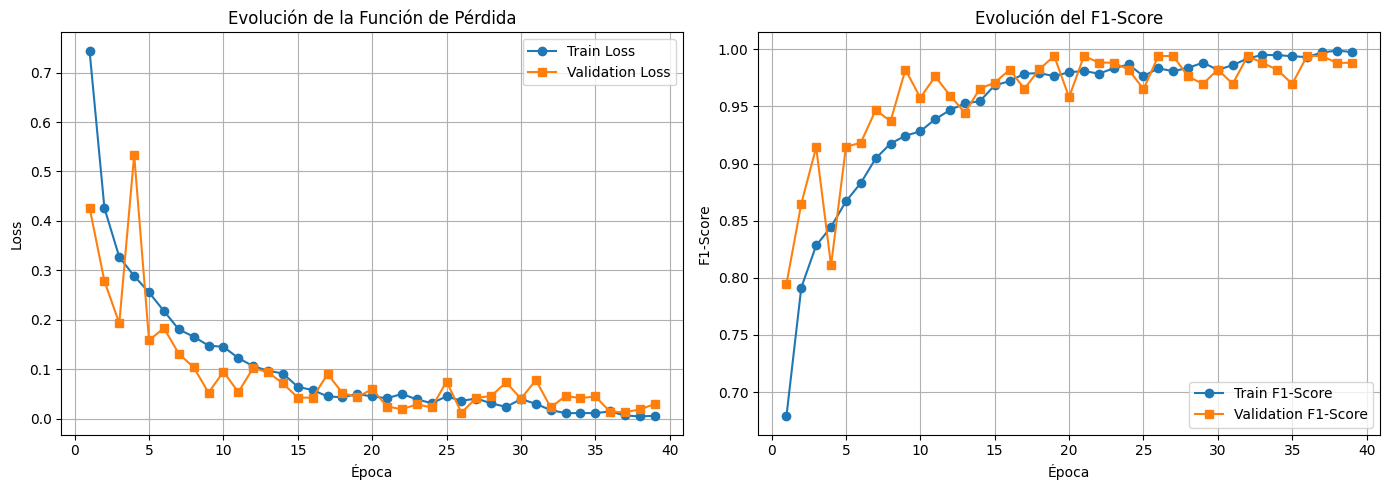

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epocas = range(1, len(history["train_loss"]) + 1)
axes[0].plot(epocas, history["train_loss"], label="Train Loss", marker="o")
axes[0].plot(epocas, history["val_loss"], label="Validation Loss", marker="s")
axes[0].set_title("Evolución de la Función de Pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epocas, history["train_f1"], label="Train F1-Score", marker="o")
axes[1].plot(epocas, history["val_f1"], label="Validation F1-Score", marker="s")
axes[1].set_title("Evolución del F1-Score")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("F1-Score")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("graficas_entrenamiento.png", dpi=300)
plt.show()

## Evaluación final

Finalmente, se cargan los mejores pesos almacenados durante el entrenamiento y se evalúa el rendimiento definitivo sobre el conjunto de prueba (test), obteniendo el F1-score, precisión, exhaustividad, tasas de falsos positivos y falsos negativos, y la matriz de confusión correspondiente.

Antes de predecir ponemos el modelo en modo evaluación, para que el dropout se desactive y el BatchNorm use sus estadísticas ya aprendidas, y usamos torch.no_grad() porque aquí no hace falta calcular gradientes. Sacamos las tasas de falsos positivos y falsos negativos porque son las que se usan para desempatar en la competición, que aunque se comentó que fuera improbable, ya lo dejamos implementado. El conjunto de test solo se usa en este punto, el modelo y los hiperparámetros se eligieron mirando validación.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_14328\3925049546.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_PATH))


F1-Score Test:  0.9942
Precision Test: 0.9884
Recall Test:    1.0000
Falsos Positivos (FP): 1 (Tasa FP: 0.0056)
Falsos Negativos (FN): 0 (Tasa FN: 0.0000)


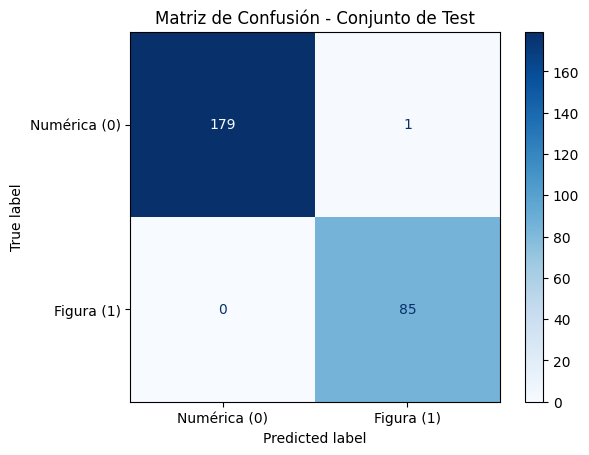

In [12]:
model.load_state_dict(torch.load(MODEL_PATH))
model.eval()

test_preds, test_targets = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        preds = (torch.sigmoid(outputs) >= 0.5).float()
        test_preds.extend(preds.cpu().numpy())
        test_targets.extend(labels.numpy())

test_f1 = f1_score(test_targets, test_preds)
test_precision = precision_score(test_targets, test_preds)
test_recall = recall_score(test_targets, test_preds)

cm = confusion_matrix(test_targets, test_preds)
tn, fp, fn, tp = cm.ravel()

print(f"F1-Score Test:  {test_f1:.4f}")
print(f"Precision Test: {test_precision:.4f}")
print(f"Recall Test:    {test_recall:.4f}")
print(f"Falsos Positivos (FP): {fp} (Tasa FP: {fp / (fp + tn):.4f})")
print(f"Falsos Negativos (FN): {fn} (Tasa FN: {fn / (fn + tp):.4f})")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Numérica (0)", "Figura (1)"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Conjunto de Test")
plt.savefig("matriz_confusion_test.png", dpi=300)
plt.show()

## Gráficas extra

Además de la matriz de confusión y las curvas de entrenamiento, añadimos algunas gráficas más para entender mejor cómo se comporta el modelo. Para casi todas necesitamos la probabilidad que da el modelo (la salida de la sigmoide) y no solo la clase final, así que primero la calculamos para validación y test. Con eso ya podemos comparar las métricas de las dos particiones. Con la validación elegimos el mejor modelo, así que si estuviera sobreajustado a ella el test saldría claramente peor. Ojo, el eje no empieza en 0 porque si no todas las barras parecerían iguales.

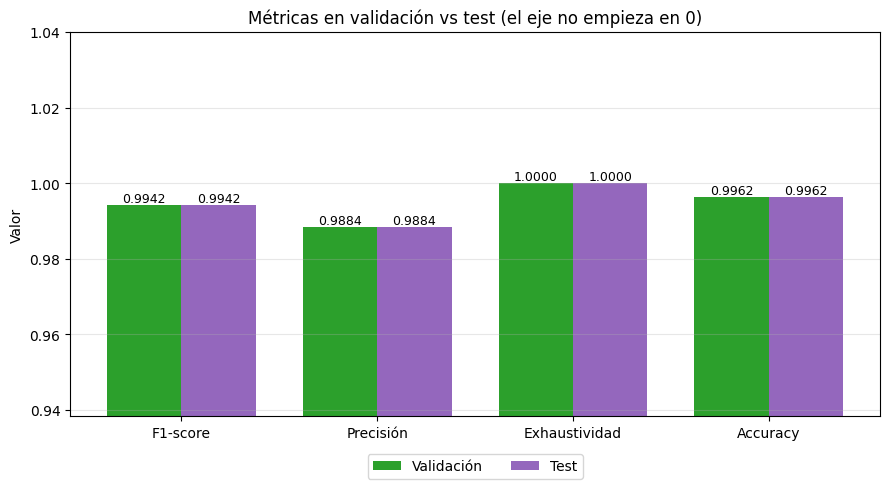

In [13]:
from sklearn.metrics import accuracy_score

def obtener_probs(loader):
    model.eval()
    probs, reales = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            salida = model(inputs.to(device))
            probs.extend(torch.sigmoid(salida).cpu().numpy().ravel())
            reales.extend(labels.numpy().ravel())
    return np.array(probs), np.array(reales).astype(int)

val_probs, val_reales = obtener_probs(val_loader)
test_probs, test_reales = obtener_probs(test_loader)
val_pred = (val_probs >= 0.5).astype(int)
test_pred = (test_probs >= 0.5).astype(int)

def calcular_metricas(y, p):
    return [f1_score(y, p), precision_score(y, p), recall_score(y, p), accuracy_score(y, p)]

nombres_metricas = ["F1-score", "Precisión", "Exhaustividad", "Accuracy"]
m_val = calcular_metricas(val_reales, val_pred)
m_test = calcular_metricas(test_reales, test_pred)

x = np.arange(len(nombres_metricas))
ancho = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - ancho / 2, m_val, ancho, label="Validación", color="tab:green")
b2 = ax.bar(x + ancho / 2, m_test, ancho, label="Test", color="tab:purple")
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{barra.get_height():.4f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(nombres_metricas)
ax.set_ylim(max(0, min(m_val + m_test) - 0.05), 1.04)
ax.set_ylabel("Valor")
ax.set_title("Métricas en validación vs test (el eje no empieza en 0)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("metricas_val_vs_test.png", dpi=300, bbox_inches="tight")
plt.show()

Aquí tenemos el histograma de las probabilidades que da el modelo en test, separadas por la clase real. Lo ideal es que las numéricas se amontonen cerca de 0 y las figuras cerca de 1, y que haya pocas en el medio, porque eso quiere decir que el modelo está seguro de lo que dice. El eje y está en escala logarítmica, ya que normalmente casi todas las imágenes caen en los extremos y, si no, las barras del medio ni se verían.

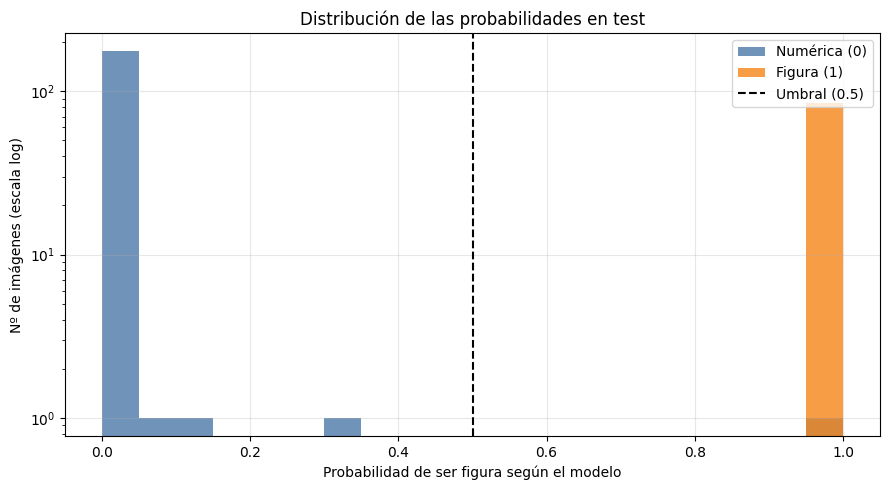

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(0, 1, 21)
ax.hist(test_probs[test_reales == 0], bins=bins, alpha=0.8, color=COLOR_NUM, label="Numérica (0)")
ax.hist(test_probs[test_reales == 1], bins=bins, alpha=0.8, color=COLOR_FIG, label="Figura (1)")
ax.axvline(0.5, color="black", linestyle="--", label="Umbral (0.5)")
ax.set_yscale("log")
ax.set_xlabel("Probabilidad de ser figura según el modelo")
ax.set_ylabel("Nº de imágenes (escala log)")
ax.set_title("Distribución de las probabilidades en test")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("distribucion_probabilidades.png", dpi=300)
plt.show()

Estas son las 8 imágenes de test en las que el modelo estaba menos seguro, es decir, con la probabilidad más cerca de 0.5. Hemos puesto estas en vez de solo los errores porque, si el modelo no falla ninguna (como espemos que haga ya que somos unos programadores excelentes), esa gráfica saldría vacía. En verde están las que acierta y en rojo las que falla.

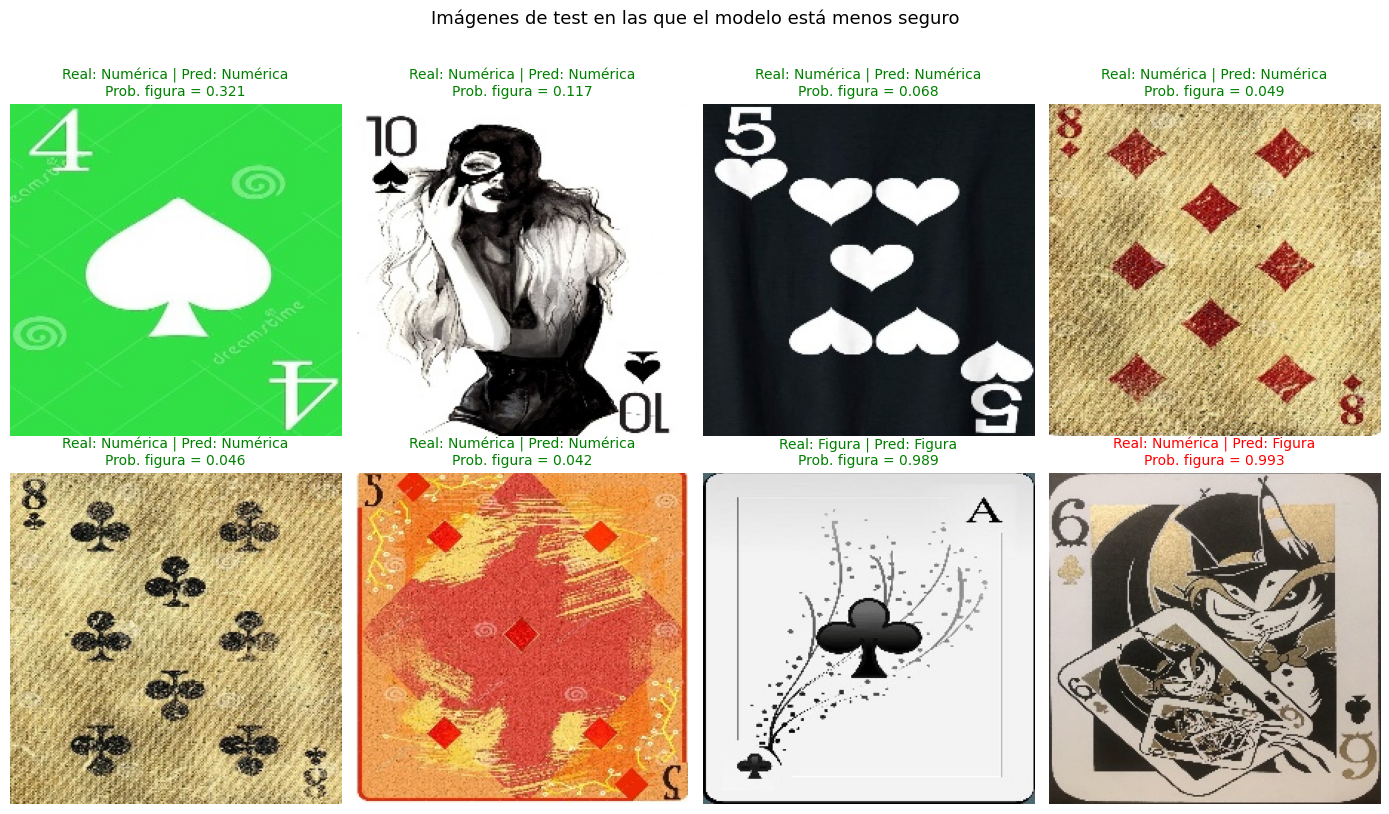

In [15]:
orden = np.argsort(np.abs(test_probs - 0.5))[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 8.5))
for ax, idx in zip(axes.flat, orden):
    ax.imshow(cv2.cvtColor(X_test[idx], cv2.COLOR_BGR2RGB))
    real = "Figura" if test_reales[idx] == 1 else "Numérica"
    pred = "Figura" if test_pred[idx] == 1 else "Numérica"
    acierto = test_reales[idx] == test_pred[idx]
    ax.set_title(f"Real: {real} | Pred: {pred}\nProb. figura = {test_probs[idx]:.3f}",
                 color="green" if acierto else "red", fontsize=10)
    ax.axis("off")
plt.suptitle("Imágenes de test en las que el modelo está menos seguro", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("imagenes_dudosas.png", dpi=300)
plt.show()

## Evolución

Empezamos con una red sencilla de cuatro bloques (Conv2d + ReLU + MaxPool2d), entrenada 20 épocas, que ya daba un F1 de test de 0.9711 con 4 falsos positivos y 1 falso negativo. Para mejorarlo fuimos tocando cosas poco a poco y mirando siempre las curvas de entrenamiento. Lo primero fue definir la función bloque() para no repetir capas, y meterle BatchNorm, LeakyReLU y dropout, además de un quinto bloque y un kernel de 5 x 5 al principio. En las primeras gráficas que vimos, nos dimos cuenta que el modelo estaba infraentrenado.

Por eso subimos las épocas de 20 a 80 y la paciencia del early stopping de 6 a 13, bajamos el dropout de 0.2 a 0.1 y pusimos dos convoluciones por bloque. También cambiamos el criterio del early stopping y del scheduler para que miren la pérdida de validación en vez del F1, porque con solo 265 imágenes el F1 sube y baja a saltos y nos bajaba el learning rate (de 0.001 a 0.00025 en 18 épocas) y cortaba el entrenamiento demasiado pronto. Por último, suavizamos el data augmentation quitando el volteo vertical y bajando la rotación de 15 a 5 grados, y añadimos weight_decay=1e-4.

Con la versión final el entrenamiento paró solo en la época 42 y el mejor modelo (época 41) llegó a un F1 de validación de 0.9882. En test no falló ninguna de las 265 imágenes (F1 de 1.0, sin falsos positivos ni falsos negativos). Eso sí, con un conjunto de test tan pequeño tampoco hay que fiarse demasiado de ese 1.0, somos conscientes de que no hemos creado el modelo divino.

## Fuentes

Gran parte del esqueleto de este cuaderno parte de plantillas y código reutilizado desarrollado previamente en otras asignaturas del grado, como Inteligencia Artificial y Machine Learning, adaptándolo en esta ocasión a arquitecturas convolucionales en PyTorch.

Además de eso, hemos visitado algunas páginas web como: [https://www.kaggle.com/datasets/gpiosenka/cards-image-datasetclassification](https://www.kaggle.com/datasets/gpiosenka/cards-image-datasetclassification)
sitio del cual hemos podido ver cómo trabajaba la gente y qué usaba (aunque muchas de estas cosas no estaban permitidas para esta práctica)